# Table of Contents
- 1. Deep-Dive Distribution Visualization (KDE, Boxen, Violin) : Kernel Density Estimation
- 2. Joint Distributions and Pairplots
- 3. Categorical vs Continuous Breakdown Analysis
- 4. Skewness and Transformation Checks

In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, boxcox

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for univariate and multivariate audits loaded successfully.")

Global libraries for univariate and multivariate audits loaded successfully.


---
## 1. Deep-Dive Distribution Visualization (KDE, Boxen, Violin)

### 1. Definition
Advanced distribution visualizations go beyond standard histograms by using Kernel Density Estimation (KDE) for smoothed continuous curves, Boxen plots for detailed quantile distributions, and Violin plots to display full probability densities alongside summary statistics.

### 4. Naive Example
Comparing employee salary distributions across multiple departments using violin plots to instantly observe multimodal peaks and density spreads rather than just mean values.

### 5. Uses
- Identifying multi-modality, skewness, and heavy tails in continuous variables.
- Comparing distribution shapes across multiple categorical groups simultaneously.
- Detecting hidden clusters or subpopulations within numerical datasets.

Distribution Summary Statistics:
 department            HR             IT
count         100.000000     100.000000
mean        55178.436696   83961.534826
std          7629.351729    9081.684280
min         39649.830278   58802.548959
25%         48554.715815   78990.943295
50%         55672.857360   83730.437082
75%         59305.363581   89059.520520
max         76761.353333  103522.781845


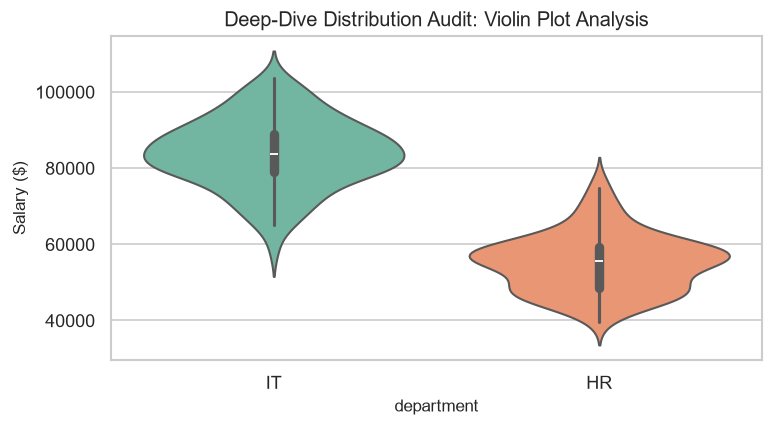

In [ ]:
np.random.seed(42)
df_dist = pd.DataFrame({
    'department': ['IT'] * 100 + ['HR'] * 100,
    'salary': np.concatenate([np.random.normal(85000, 10000, 100), np.random.normal(55000, 8000, 100)])
})
print("Distribution Summary Statistics:\n", df_dist.groupby('department')['salary'].describe().T)
# Visualization
plt.figure(figsize=(7, 3.5))
# sns.violinplot(x='department', y='salary', data=df_dist, palette='Set2') # old with warning
# pallet : deep, muted pastel, bright . dark , colorblind, Set2(ColorBrewer)
sns.violinplot(x='department', y='salary', hue='department', data=df_dist, palette='Set2', legend=False)
plt.title('Deep-Dive Distribution Audit: Violin Plot Analysis')
plt.ylabel('Salary ($)')
plt.show()

## 2. Joint Distributions and Pairplots

### 1. Definition
Joint distribution analysis and pairplots map pairwise relationships across all numerical columns in a dataset, combining scatter plots for bivariate interactions with univariate histograms or KDEs along the diagonal.

### 4. Naive Example
Plotting a pairplot of customer financial metrics (`income`, `spending_score`, `age`) to immediately spot linear correlations and distinct customer clusters.

### 5. Uses
- Exploring multivariate relationships and linear dependencies.
- Identifying collinearity and interaction effects prior to modeling.
- Visualizing multi-class separation for classification tasks.

Correlation Matrix:
            feature_a  feature_b
feature_a   1.000000  -0.136422
feature_b  -0.136422   1.000000


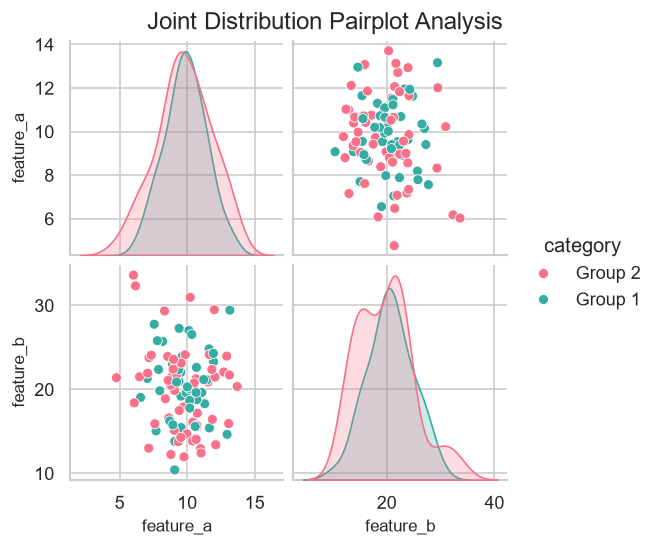

In [10]:
np.random.seed(42)
df_joint = pd.DataFrame({
    'feature_a': np.random.normal(10, 2, 100),
    'feature_b': np.random.normal(20, 5, 100),
    'category': np.random.choice(['Group 1', 'Group 2'], 100)
})
# Correlation matrix check
print("Correlation Matrix:\n", df_joint[['feature_a', 'feature_b']].corr())

# Visualization
sns.pairplot(df_joint, hue='category', height=2.2, palette='husl')
plt.suptitle('Joint Distribution Pairplot Analysis', y=1.02)
plt.show()

## 3. Categorical vs Continuous Breakdown Analysis

###  Definition
Categorical versus continuous breakdown analysis evaluates how numerical metrics vary across discrete categorical segments using grouped summary statistics, box plots, and bar charts with error bars.


###  Naive Example
Analyzing average customer purchase amounts broken down by geographic region and product category to identify top-performing market segments.

###  Uses
- Uncovering key drivers and segment-specific performance differences.
- Testing hypotheses about group mean differences.
- Informing feature engineering and categorical encoding choices.

In [11]:
df_breakdown = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South', 'East', 'East'],
    'sales': [250, 300, 450, 400, 150, 180]
})

segment_summary = df_breakdown.groupby('region')['sales'].agg(['mean', 'median', 'std']).reset_index()
print(
    "Segment Breakdown Summary:\n",
    segment_summary.to_string(index=False),
)

Segment Breakdown Summary:
 region  mean  median       std
  East 165.0   165.0 21.213203
 North 275.0   275.0 35.355339
 South 425.0   425.0 35.355339


---
## 4. Skewness and Transformation Checks

###  Definition
Skewness measures asymmetry in a probability distribution. Transformation checks apply mathematical functions (such as Log, Box-Cox, or Yeo-Johnson) to correct heavy skewness and stabilize variance for parametric modeling.

### Naive Example
Applying a log transformation to a heavily right-skewed income distribution so the data approximates a normal distribution prior to running linear regression.

### Uses
- Meeting normality assumptions required by parametric statistical tests and linear models.
- Improving gradient descent convergence rates in machine learning algorithms.
- Reducing the distorting impact of extreme outliers.

Original Skewness: 1.4409012249947706
Log-Transformed Skewness: 0.33730012283200667


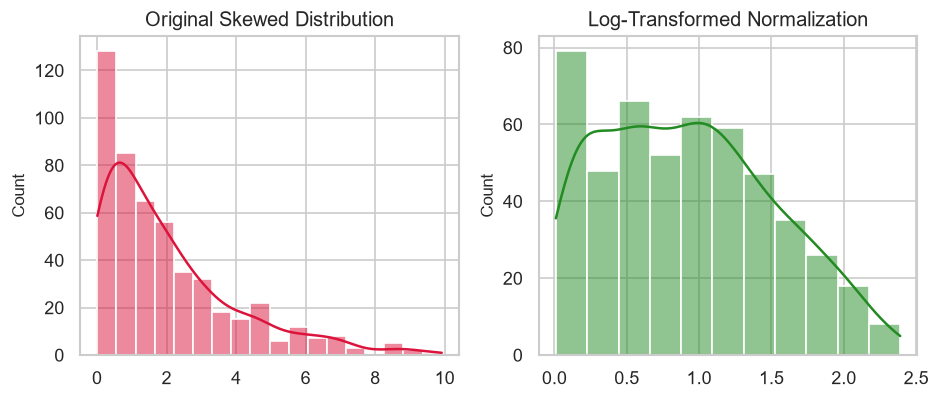

In [14]:
np.random.seed(42)
skewed_data = np.random.exponential(scale=2.0, size=500)
log_transformed = np.log1p(skewed_data)

print("Original Skewness:", skew(skewed_data))
print("Log-Transformed Skewness:", skew(log_transformed))


# Visualization
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
sns.histplot(skewed_data, kde=True, ax=axes[0], color='crimson')
axes[0].set_title('Original Skewed Distribution')
sns.histplot(log_transformed, kde=True, ax=axes[1], color='forestgreen')
axes[1].set_title('Log-Transformed Normalization')
plt.tight_layout()
plt.show()


In [17]:
import numpy as np
from scipy import stats

positive_data = np.array([1.0, 2.0, 5.0, 10.0, 100.0])

transformed_boxcox, fitted_lambda = stats.boxcox(positive_data)

print("Original Data:", positive_data)
print("Box-Cox Transformed:", np.round(transformed_boxcox, 2))
print(f"Optimal Lambda found by Box-Cox: {fitted_lambda:.2f}")

Original Data: [  1.   2.   5.  10. 100.]
Box-Cox Transformed: [0.   0.64 1.32 1.74 2.71]
Optimal Lambda found by Box-Cox: -0.25


In [18]:
import numpy as np
from scipy import stats

# 1. Create data with negative numbers, zeros, and positives
mixed_data = np.array([-5.0, -1.0, 0.0, 3.0, 50.0])

# 2. Apply Yeo-Johnson transformation
transformed_yeojohnson, fitted_lambda_yj = stats.yeojohnson(mixed_data)

print("Original Data (with negatives):", mixed_data)
print("Yeo-Johnson Transformed:", np.round(transformed_yeojohnson, 2))
print(f"Optimal Lambda found by Yeo-Johnson: {fitted_lambda_yj:.2f}")

Original Data (with negatives): [-5. -1.  0.  3. 50.]
Yeo-Johnson Transformed: [-10.1   -1.26   0.     1.88  10.03]
Optimal Lambda found by Yeo-Johnson: 0.42
